In [8]:
import pandas as pd

In [9]:
df_sales = pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\DA using Python\sales\sales-transactions-5000.csv'
)

df_products= pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\KPMG sem3\DA using Python\sales\products-30-rows.csv")

df_customer = pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\DA using Python\sales\customers-500-rows.csv')

In [10]:
df_sales.head(10
)


,Transaction_ID,Customer_ID,Product_ID,Order_Date,Quantity,Discount_Pct,Payment_Method,Sales_Channel,Region,Unit_Price,Gross_Sales,Discount_Amount,Net_Sales
0,T000001,C0459,P009,2024-12-28,3.0,10.0,UPI,Mobile App,East,25603.21,76809.63,7680.96,69128.67
1,T000002,C0466,P007,2025-10-30,2.0,30.0,Cash on Delivery,Online,East,903.59,1807.18,542.15,1265.03
2,T000003,C0012,P013,2026-05-24,1.0,10.0,Debit Card,Store,East,45219.58,45219.58,4521.96,40697.62
3,T000004,C0087,P002,2024-12-24,2.0,10.0,Debit Card,Store,Central,37890.85,75781.70,7578.17,68203.53
4,T000005,C0012,P008,2025-12-06,4.0,30.0,UPI,Store,South,4848.18,19392.72,5817.82,13574.90
5,T000006,C0397,P007,2026-02-25,3.0,15.0,Credit Card,Store,East,903.59,2710.77,406.62,2304.15
6,T000007,C0025,P024,2024-11-19,6.0,15.0,UPI,Store,North,45704.85,274229.10,41134.36,233094.74
7,T000008,C0301,P012,2025-11-28,2.0,15.0,Credit Card,Store,Central,19064.32,38128.64,5719.30,32409.34
8,T000009,C0243,P019,2024-11-21,1.0,30.0,Cash on Delivery,Store,East,15846.62,15846.62,4753.99,11092.63
9,T000010,C0122,P007,2025-09-16,8.0,15.0,Cash on Delivery,Online,Central,903.59,7228.72,1084.31,6144.41


In [11]:
df_customer.head()

,Customer_ID,Customer_Name,City,Customer_Segment,Signup_Date
0,C0001,Customer_0001,Vadodara,Consumer,2022-05-31
1,C0002,Customer_0002,Hyderabad,Small Business,2025-01-13
2,C0003,Customer_0003,Jaipur,Consumer,2022-05-27
3,C0004,Customer_0004,Pune,Corporate,2025-11-05
4,C0005,Customer_0005,Vadodara,Consumer,2024-07-03


In [12]:
df_sales.head()

,Transaction_ID,Customer_ID,Product_ID,Order_Date,Quantity,Discount_Pct,Payment_Method,Sales_Channel,Region,Unit_Price,Gross_Sales,Discount_Amount,Net_Sales
0,T000001,C0459,P009,2024-12-28,3.0,10.0,UPI,Mobile App,East,25603.21,76809.63,7680.96,69128.67
1,T000002,C0466,P007,2025-10-30,2.0,30.0,Cash on Delivery,Online,East,903.59,1807.18,542.15,1265.03
2,T000003,C0012,P013,2026-05-24,1.0,10.0,Debit Card,Store,East,45219.58,45219.58,4521.96,40697.62
3,T000004,C0087,P002,2024-12-24,2.0,10.0,Debit Card,Store,Central,37890.85,75781.70,7578.17,68203.53
4,T000005,C0012,P008,2025-12-06,4.0,30.0,UPI,Store,South,4848.18,19392.72,5817.82,13574.90


In [14]:
print("Statistical description")

print(f"Average net sales: {df_sales['Net_Sales'].mean():.2f}")
print(f"Average unit price: {df_sales['Unit_Price'].mean():.2f}")
print(f"Average discount amount: {df_sales['Discount_Amount'].mean():.2f}")

print("Customer segments:", df_customer["Customer_Segment"].unique())

Statistical description
Average net sales: 75829.43
Average unit price: 26610.72
Average discount amount: 10394.11
Customer segments: ['Consumer' 'Small Business' 'Corporate']


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
numeric_data= df_sales[
    ['Quantity', 'Discount_Pct', "Unit_Price",
     "Gross_Sales", "Discount_Amount", "Net_Sales"]
]

In [ ]:
correlation_matrix = numeric_data.corr()
print(correlation_matrix)

                 Quantity  Discount_Pct  Unit_Price  Gross_Sales  \
Quantity         1.000000      0.015606   -0.009746     0.743461   
Discount_Pct     0.015606      1.000000   -0.000962     0.003986   
Unit_Price      -0.009746     -0.000962    1.000000     0.459459   
Gross_Sales      0.743461      0.003986    0.459459     1.000000   
Discount_Amount  0.558393      0.360311    0.307077     0.723209   
Net_Sales        0.731858     -0.068893    0.460018     0.990022   

                 Discount_Amount  Net_Sales  
Quantity                0.558393   0.731858  
Discount_Pct            0.360311  -0.068893  
Unit_Price              0.307077   0.460018  
Gross_Sales             0.723209   0.990022  
Discount_Amount         1.000000   0.618673  
Net_Sales               0.618673   1.000000  


<Axes: >

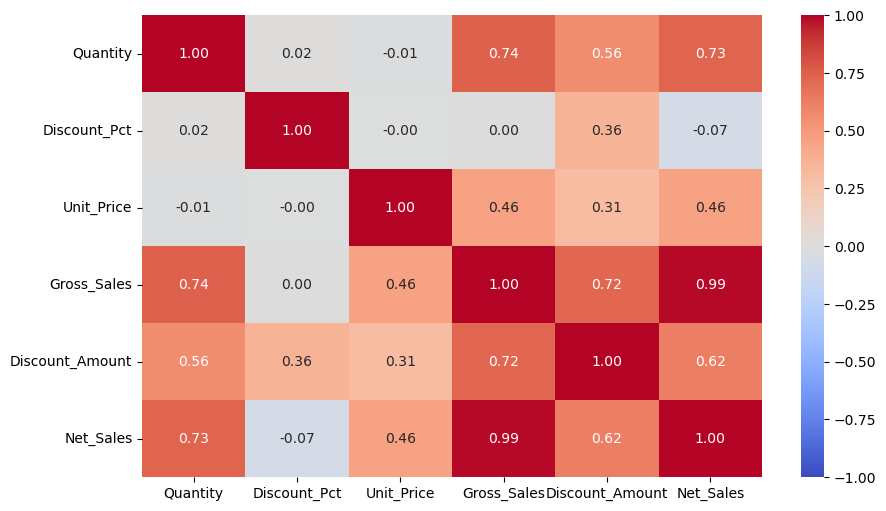

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt = ".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

In [ ]:
# using apply()

def sales_category(amount):

    if amount >= 50000:
        return "High"
    elif amount >= 20000:
        return "Medium"
    else:
        return "Low"

# apply the function to each sales value

df_sales["Sales_Category"] = df_sales["Net_Sales"].apply(sales_category)

print(df_sales[["Net_Sales", "Sales_Category"]].head())



   Net_Sales Sales_Category
0   69128.67           High
1    1265.03            Low
2   40697.62         Medium
3   68203.53           High
4   13574.90            Low


In [15]:
# Map sales channels to readable channel types
channel_mapping = {
    "Online": "E-Commerce",
    "Store": "Physical Store",
    "Mobile App": "Digital App"
}

df_sales["Channel_Type"] = df_sales["Sales_Channel"].map(channel_mapping)

print(df_sales[["Sales_Channel", "Channel_Type"]].head())

  Sales_Channel    Channel_Type
0    Mobile App     Digital App
1        Online      E-Commerce
2         Store  Physical Store
3         Store  Physical Store
4         Store  Physical Store


In [ ]:
# Binning with pd.cut()

df_sales["Quantity_Category"] = pd.cut(
    df_sales["Quantity"],
    bins =[0,2,5,10,100],
    labels=['low','Medium', 'High', 'Very High']


)
# Display the quantity categories
print(df_sales[["Quantity", 'Quantity_Category']].head())

   Quantity Quantity_Category
0       3.0            Medium
1       2.0               low
2       1.0               low
3       2.0               low
4       4.0            Medium


In [ ]:
# Aggregate using group() and agg()
# Calculate multiple statistics for each region

region_summary  = df_sales.groupby("Region").agg(
    Total_Sales = ("Net_Sales", "sum"),
    Average_Sales = ("Net_Sales", "mean"),
    Total_Quantity=("Quantity", "sum"),
    Transaction_count =("Transaction_ID", "count")

)
print(region_summary)

         Total_Sales  Average_Sales  Total_Quantity  Transaction_count
Region                                                                
Central  74640839.57   74048.451954          3178.0               1008
East     78407997.23   80171.776309          3188.0                978
North    80665499.76   80264.178866          3554.0               1005
South    73269771.95   73490.242678          3135.0                997
West     69769385.48   71779.203169          2980.0                972


In [16]:
df_sales["Channel_Type"] = df_sales["Sales_Channel"].map(channel_mapping)

print(df_sales[["Sales_Channel", "Channel_Type"]].head())

  Sales_Channel    Channel_Type
0    Mobile App     Digital App
1        Online      E-Commerce
2         Store  Physical Store
3         Store  Physical Store
4         Store  Physical Store


In [17]:
// # Calculate each region's average sales
df_sales["Region_Average_Sales"] = (
    df_sales.groupby("Region")["Net_Sales"].transform("mean")
)

// # Calculate the difference between each transaction and its regional average
df_sales["Difference_From_Region_Average"] = (
    df_sales["Net_Sales"] - df_sales["Region_Average_Sales"]
)

In [18]:
df_sales["Region_Sales_Share"] = (
    df_sales["Net_Sales"]
    / df_sales.groupby("Region")["Net_Sales"].transform("sum")
) 

In [19]:
print(df_sales.isnull().sum())

Transaction_ID                     0
Customer_ID                        0
Product_ID                         0
Order_Date                         0
Quantity                          60
Discount_Pct                      74
Payment_Method                    60
Sales_Channel                     50
Region                            40
Unit_Price                         0
Gross_Sales                        0
Discount_Amount                    0
Net_Sales                          0
Channel_Type                      50
Region_Average_Sales              40
Difference_From_Region_Average    40
Region_Sales_Share                40
dtype: int64


In [ ]:
# convert and extract date component 
# convert order_Date to datetime formAT

df_sales["Order_Date"] = pd.to_datetime(
    df_sales["Order_Date"]
)

# Extract year month and day

df_sales["Year"] = df_sales["Order_Date"].dt.year
df_sales["Month"] = df_sales["Order_Date"].dt.month
df_sales["Day"]  = df_sales["Order_Date"].dt.day

In [ ]:
monthly_sales = df_sales.groupby(
    ["Year", "Month"]

).agg(
    Total_Sales =("Net_Sales", "sum"),
    Total_Quality = ("Quantity", "sum"),
    Transaction_Count =("Transaction_ID", "count")
)
print(monthly_sales)

            Total_Sales  Total_Quality  Transaction_Count
Year Month                                               
2024 1      11080172.91          491.0                158
     2      10300884.96          426.0                135
     3      11113495.26          440.0                159
     4      10334992.66          446.0                134
     5      13041061.36          512.0                153
     6      11742133.35          516.0                155
     7      10192185.07          471.0                140
     8       9269530.32          505.0                145
     9      12143199.25          506.0                170
     10     10122898.87          418.0                128
     11     12688162.88          508.0                156
     12     12096794.13          544.0                145
2025 1      10524207.30          449.0                148
     2       9672429.70          405.0                130
     3      14145429.54          553.0                150
     4      14

In [ ]:
df_sales = df_sales.set_index("Order_Date")

#Rolling calculations and moving averages
# Calculate daily sales totals
daily_sales = df_sales["Net_Sales"].resample("D").sum()

# Calculate a 7-day moving average
daily_sales_7day = daily_sales.rolling(window=7).mean()

# Calculate a 30-day moving average
daily_sales_30day = daily_sales.rolling(window=30).mean()

# Display the results
print(daily_sales_7day.tail())
print(daily_sales_30day.tail())

# Plot daily sales and moving averages
plt.figure(figsize=(12, 5))

Order_Date
2026-09-22    519640.307143
2026-09-23    495137.251429
2026-09-24    518583.257143
2026-09-25    422029.718571
2026-09-26    386896.450000
Freq: D, Name: Net_Sales, dtype: float64
Order_Date
2026-09-22    395813.752333
2026-09-23    402404.668667
2026-09-24    419079.527667
2026-09-25    394650.111000
2026-09-26    382205.962333
Freq: D, Name: Net_Sales, dtype: float64


<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

In [24]:
# Merge sales and customer data using an inner join.
# This keeps only sales records whose Customer_ID exists in df_customer.
sales_customer = pd.merge(
    df_sales,
    df_customer,
    on="Customer_ID",
    how="inner"
)

# Display the merged data and verify its dimensions.
display(sales_customer.head())
print("Merged data shape:", sales_customer.shape)

,Transaction_ID,Customer_ID,Product_ID,Order_Date,Quantity,Discount_Pct,Payment_Method,Sales_Channel,Region,Unit_Price,...,Discount_Amount,Net_Sales,Channel_Type,Region_Average_Sales,Difference_From_Region_Average,Region_Sales_Share,Customer_Name,City,Customer_Segment,Signup_Date
0,T000001,C0459,P009,2024-12-28,3.0,10.0,UPI,Mobile App,East,25603.21,...,7680.96,69128.67,Digital App,80171.776309,-11043.106309,0.000882,Customer_0459,Delhi,Consumer,2023-07-24
1,T000002,C0466,P007,2025-10-30,2.0,30.0,Cash on Delivery,Online,East,903.59,...,542.15,1265.03,E-Commerce,80171.776309,-78906.746309,0.000016,Customer_0466,Chennai,Consumer,2022-02-08
2,T000003,C0012,P013,2026-05-24,1.0,10.0,Debit Card,Store,East,45219.58,...,4521.96,40697.62,Physical Store,80171.776309,-39474.156309,0.000519,Customer_0012,Jaipur,Small Business,2024-01-16
3,T000004,C0087,P002,2024-12-24,2.0,10.0,Debit Card,Store,Central,37890.85,...,7578.17,68203.53,Physical Store,74048.451954,-5844.921954,0.000914,Customer_0087,Bengaluru,Consumer,2023-09-26
4,T000005,C0012,P008,2025-12-06,4.0,30.0,UPI,Store,South,4848.18,...,5817.82,13574.90,Physical Store,73490.242678,-59915.342678,0.000185,Customer_0012,Jaipur,Small Business,2024-01-16


Merged data shape: (5000, 21)


In [25]:
# Left join to keep all sales records and add customer details where available
sales_customer_left = pd.merge(
    df_sales,
    df_customer,
    on="Customer_ID",
    how="left"
)

display(sales_customer_left.head())
print("Left-join shape:", sales_customer_left.shape)
print("Sales rows retained:", sales_customer_left.shape[0] == df_sales.shape[0])

,Transaction_ID,Customer_ID,Product_ID,Order_Date,Quantity,Discount_Pct,Payment_Method,Sales_Channel,Region,Unit_Price,...,Discount_Amount,Net_Sales,Channel_Type,Region_Average_Sales,Difference_From_Region_Average,Region_Sales_Share,Customer_Name,City,Customer_Segment,Signup_Date
0,T000001,C0459,P009,2024-12-28,3.0,10.0,UPI,Mobile App,East,25603.21,...,7680.96,69128.67,Digital App,80171.776309,-11043.106309,0.000882,Customer_0459,Delhi,Consumer,2023-07-24
1,T000002,C0466,P007,2025-10-30,2.0,30.0,Cash on Delivery,Online,East,903.59,...,542.15,1265.03,E-Commerce,80171.776309,-78906.746309,0.000016,Customer_0466,Chennai,Consumer,2022-02-08
2,T000003,C0012,P013,2026-05-24,1.0,10.0,Debit Card,Store,East,45219.58,...,4521.96,40697.62,Physical Store,80171.776309,-39474.156309,0.000519,Customer_0012,Jaipur,Small Business,2024-01-16
3,T000004,C0087,P002,2024-12-24,2.0,10.0,Debit Card,Store,Central,37890.85,...,7578.17,68203.53,Physical Store,74048.451954,-5844.921954,0.000914,Customer_0087,Bengaluru,Consumer,2023-09-26
4,T000005,C0012,P008,2025-12-06,4.0,30.0,UPI,Store,South,4848.18,...,5817.82,13574.90,Physical Store,73490.242678,-59915.342678,0.000185,Customer_0012,Jaipur,Small Business,2024-01-16


Left-join shape: (5000, 21)
Sales rows retained: True


In [26]:
# Right join to keep all customer records and add sales details where available
sales_customer_right = pd.merge(
    df_sales,
    df_customer,
    on="Customer_ID",
    how="right"
)

display(sales_customer_right.head())
print("Right-join shape:", sales_customer_right.shape)
print("Customer rows retained:", sales_customer_right.shape[0] == df_customer.shape[0])

,Transaction_ID,Customer_ID,Product_ID,Order_Date,Quantity,Discount_Pct,Payment_Method,Sales_Channel,Region,Unit_Price,...,Discount_Amount,Net_Sales,Channel_Type,Region_Average_Sales,Difference_From_Region_Average,Region_Sales_Share,Customer_Name,City,Customer_Segment,Signup_Date
0,T000157,C0001,P012,2026-05-22,6.0,0.0,Debit Card,Store,East,19064.32,...,0.00,114385.92,Physical Store,80171.776309,34214.143691,0.001459,Customer_0001,Vadodara,Consumer,2022-05-31
1,T000191,C0001,P021,2024-05-25,1.0,15.0,Cash on Delivery,Online,East,9390.84,...,1408.63,7982.21,E-Commerce,80171.776309,-72189.566309,0.000102,Customer_0001,Vadodara,Consumer,2022-05-31
2,T000272,C0001,P005,2024-11-06,3.0,30.0,Cash on Delivery,Online,South,20276.97,...,18249.27,42581.64,E-Commerce,73490.242678,-30908.602678,0.000581,Customer_0001,Vadodara,Consumer,2022-05-31
3,T001674,C0001,P009,2025-05-08,4.0,15.0,Cash on Delivery,Mobile App,North,25603.21,...,15361.93,87050.91,Digital App,80264.178866,6786.731134,0.001079,Customer_0001,Vadodara,Consumer,2022-05-31
4,T001950,C0001,P009,2025-02-20,6.0,15.0,Net Banking,Online,South,25603.21,...,23042.89,130576.37,E-Commerce,73490.242678,57086.127322,0.001782,Customer_0001,Vadodara,Consumer,2022-05-31


Right-join shape: (5000, 21)
Customer rows retained: False


In [27]:
# Outer join: keep all matching and non-matching records
sales_customer_outer = pd.merge(
    df_sales,
    df_customer,
    on="Customer_ID",
    how="outer",
    indicator=True
)

display(sales_customer_outer.head())
print("Outer-join shape:", sales_customer_outer.shape)
print(sales_customer_outer["_merge"].value_counts())

,Transaction_ID,Customer_ID,Product_ID,Order_Date,Quantity,Discount_Pct,Payment_Method,Sales_Channel,Region,Unit_Price,...,Net_Sales,Channel_Type,Region_Average_Sales,Difference_From_Region_Average,Region_Sales_Share,Customer_Name,City,Customer_Segment,Signup_Date,_merge
0,T000157,C0001,P012,2026-05-22,6.0,0.0,Debit Card,Store,East,19064.32,...,114385.92,Physical Store,80171.776309,34214.143691,0.001459,Customer_0001,Vadodara,Consumer,2022-05-31,both
1,T000191,C0001,P021,2024-05-25,1.0,15.0,Cash on Delivery,Online,East,9390.84,...,7982.21,E-Commerce,80171.776309,-72189.566309,0.000102,Customer_0001,Vadodara,Consumer,2022-05-31,both
2,T000272,C0001,P005,2024-11-06,3.0,30.0,Cash on Delivery,Online,South,20276.97,...,42581.64,E-Commerce,73490.242678,-30908.602678,0.000581,Customer_0001,Vadodara,Consumer,2022-05-31,both
3,T001674,C0001,P009,2025-05-08,4.0,15.0,Cash on Delivery,Mobile App,North,25603.21,...,87050.91,Digital App,80264.178866,6786.731134,0.001079,Customer_0001,Vadodara,Consumer,2022-05-31,both
4,T001950,C0001,P009,2025-02-20,6.0,15.0,Net Banking,Online,South,25603.21,...,130576.37,E-Commerce,73490.242678,57086.127322,0.001782,Customer_0001,Vadodara,Consumer,2022-05-31,both


Outer-join shape: (5000, 22)
_merge
both          5000
left_only        0
right_only       0
Name: count, dtype: int64


In [ ]:
# Outer join 
# Outer join: keep all matching and non matching records 


